# Gene Subcellular Localization Analysis

In [83]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from functools import reduce
import operator
from adjustText import adjust_text
import harmonypy as hm

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *
from utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

## 1. Loading data

In [84]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)

## 2. Loading CellProfiler Features per Each Gene

In [5]:
feat = "GFP"
gene_list = imaging_summary_clinvar.unique("Gene")["Gene"].to_list()
bio_reps = list(imaging_summary_clinvar["Metadata_Bio_Batch"].unique())

In [85]:
# allele_meta_df = pl.DataFrame()
# allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     for batch_id in bio_rep_batches:
#         allele_meta_df_batch = pl.DataFrame()
#         platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
#         for platemap in platemaps:
#             platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
#             allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
#                                         platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
#                                         how="diagonal_relaxed").sort("plate_map_name")
#             allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
#             # display(allele_meta_df.head())
#         allele_meta_df = pl.concat([
#             allele_meta_df,
#             allele_meta_df_batch
#         ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
#     allele_meta_df_dict[bio_rep] = allele_meta_df_batch

#     img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
#     img_well_qc_sum = img_well_qc_sum.with_columns(
#         pl.col("channel").replace("DAPI", "DNA").alias("channel")
#     )
#     img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
#     img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
#         pl.col("is_bg").max().alias("is_bg"),
#         pl.col("s2n_ratio").mean().alias("s2n_ratio")
#     ).with_columns(pl.lit("Morph").alias("channel"))
#     img_well_qc_sum = pl.concat([
#         img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
#         img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
#     ], how="vertical_relaxed")
#     img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

### 2.1 CP features per each gene

#### Cell QC info

In [86]:
# # Paths
# ref_var_cell_qc_prof_df = pl.DataFrame()
# target_gene_alleles = []
# meta_cols = [
#     "Metadata_CellID",
#     "Metadata_gene_allele",
#     "Metadata_Well",
#     "Metadata_Plate",
#     "Metadata_node_type"
# ]

# # Get meta features
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     ## ONLY grep the allele come from the bio-rep
#     allele_batch_df = imaging_summary_clinvar.filter(pl.col("Metadata_Bio_Batch")==bio_rep)
#     batch_allele_list = [gene for gene in gene_list if gene in list(allele_batch_df["Gene"].unique())]
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 PASS_QC_PROF_PQ.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(batch_allele_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         ).collect()
#         # feat_cols = [col for col in batch_alleles.columns if feat.lower() in col.lower()]
#         batch_alleles = batch_alleles.join(
#             img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==feat).select(pl.col("plate", "well", "is_bg")),
#             left_on=["Metadata_Plate", "Metadata_Well"],
#             right_on=["plate", "well"]
#         ).filter(
#             ~pl.col("is_bg")
#         ).select(pl.col(meta_cols))
#         ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

In [87]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(gene_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# if feat == "Morph":
#     all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) \
#                                                     and ("Brightfield".lower() not in col.lower() and "GFP".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# else:
#     all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (feat.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))

# select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])
# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", how="left", coalesce=True)

In [88]:
# ref_var_cell_all_prof_df.shape

In [89]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.join(
#     gene_loc_all_df.select(
#         pl.col(["Gene name", "Main location", "Approved", "Approved_Final_Loc"])
#     ).rename(
#         {
#             "Main location": "Metadata_hpa_main_loc",
#             "Approved": "Metadata_hpa_approved",
#             "Approved_Final_Loc": "Metadata_final_loc"
#         }
#     ),
#     left_on="Metadata_gene_allele",
#     right_on="Gene name",
#     how="left"
# )

In [90]:
# # Extract features once
# feature_cols = [c for c in ref_var_cell_all_prof_df.columns if "Metadata" not in c]
# # features = ref_var_cell_all_prof_df.select(pl.col(feature_cols))

# # Standardize by INT and fit PCA
# data_scaled = inverse_normal_transform(ref_var_cell_all_prof_df, feature_cols)

In [130]:
ref_var_cell_all_prof_df = pl.read_parquet("../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc.parquet")
ref_var_cell_featsel_prof_df = pl.read_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_int_featselect.parquet"
)
ref_var_cell_dr_embeddings_df = pl.read_parquet(
    "../1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/ref_var_gfp_feat_sc_cp_profiles_oneperc_dr_embeddings.parquet"
).with_columns(
    pl.col("Metadata_final_loc").str.to_lowercase().alias("Metadata_final_loc")
)

In [93]:
ref_var_cell_dr_embeddings_df.shape

(2856956, 8)

In [131]:
ref_var_cell_dr_embeddings_df.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_")
).unique("Metadata_final_loc").sort("Metadata_final_loc")["Metadata_final_loc"].to_list()

[None,
 'acrosome;end piece;mid piece;principal piece',
 'actin filaments',
 'actin filaments;cytosol',
 'annulus;end piece;mid piece;principal piece',
 'basal body',
 'basal body;cytosol;plasma membrane',
 'basal body;microtubules;primary cilium;vesicles',
 'centriolar satellite;cytokinetic bridge;nucleoli;nucleoplasm',
 'cytokinetic bridge;microtubules',
 'cytoplasmic',
 'cytoplasmic;vesicles',
 'cytosol',
 'cytosol;golgi apparatus',
 'cytosol;intermediate filaments',
 'cytosol;nuclear speckles',
 'cytosol;nucleoplasm',
 'cytosol;plasma membrane',
 'cytosol;vesicles',
 'end piece;flagellar centriole;mid piece;principal piece',
 'end piece;mid piece;principal piece;vesicles',
 'endoplasmic reticulum',
 'golgi apparatus',
 'golgi apparatus;rods & rings',
 'membrane',
 'microtubules',
 'mitochondria',
 'mitochondria;nucleoplasm',
 'nuclear_membrane',
 'nucleolus_fc_dfc',
 'nucleoplasm',
 'nucleoplasm;vesicles',
 'plasma membrane',
 'rods & rings',
 'uncertain',
 'vesicles']

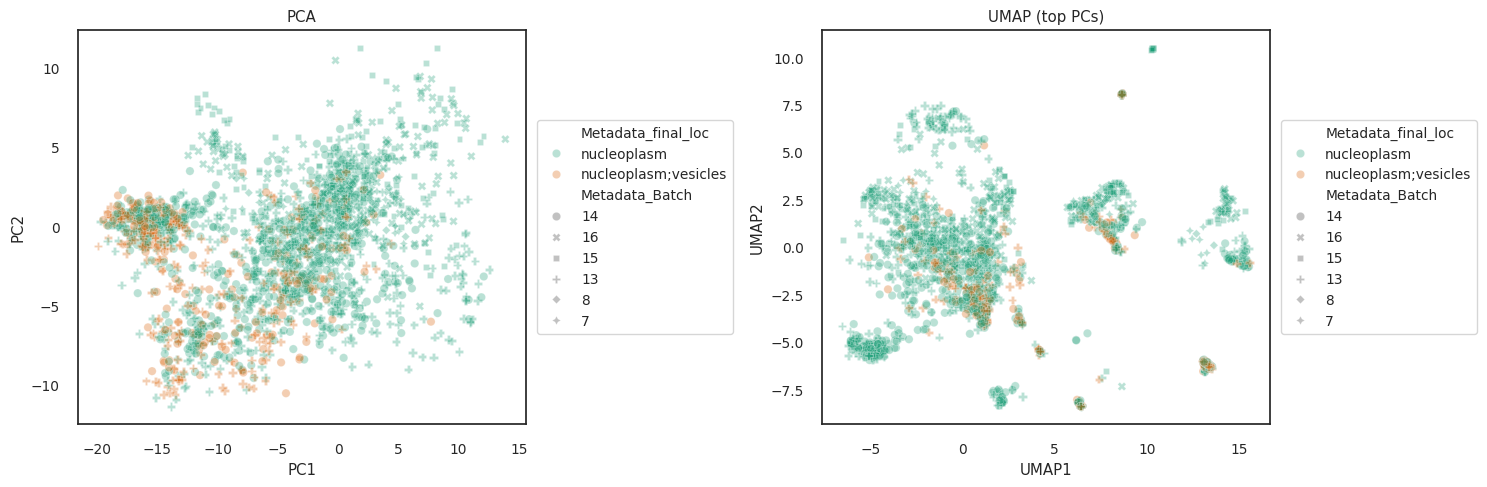

In [142]:
# Plot side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(
    data=ref_var_cell_dr_embeddings_df.filter(
        ~pl.col("Metadata_gene_allele").str.contains("_"),
        pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
    ).sample(fraction=0.1, seed=0).to_pandas(),
    x="PC1",
    y="PC2",
    hue="Metadata_final_loc",
    style="Metadata_Batch",
    palette="Dark2",
    ax=ax1,
    alpha=.3
)
# PCA plot
# scatter1 = ax1.scatter(data_results['PC1'], data_results['PC2'], 
#                      c=data_results['Metadata_Batch'].astype(int), cmap='tab10', alpha=0.6)
# ax1.set_xlabel('PC1')
# ax1.set_ylabel('PC2')
ax1.set_title('PCA')
ax1.legend(bbox_to_anchor=(1.01, 0.5), loc='center left', 
           frameon=True, title="", ncol=1)
# ax1.get_legend().remove()


# UMAP plot
sns.scatterplot(
    data=ref_var_cell_dr_embeddings_df.filter(
        ~pl.col("Metadata_gene_allele").str.contains("_"),
        pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
    ).sample(fraction=0.1, seed=0).to_pandas(),
    x="UMAP1",
    y="UMAP2",
    style="Metadata_Batch",
    hue="Metadata_final_loc",
    palette="Dark2",
    ax=ax2,
    alpha=.3
)
ax2.set_title('UMAP (top PCs)')
ax2.legend(bbox_to_anchor=(1.01, 0.5), loc='center left', 
           frameon=True, title="", ncol=1)
plt.subplots_adjust(wspace=0.3)
plt.tight_layout()
plt.show()

In [137]:
ref_var_cell_dr_embeddings_df.filter(
    ~pl.col("Metadata_gene_allele").str.contains("_"),
    pl.col("Metadata_final_loc").str.to_lowercase().str.starts_with("nucleoplasm")
).unique(subset=["Metadata_final_loc", "Metadata_gene_allele"])

PC1,PC2,UMAP1,UMAP2,Metadata_CellID,Metadata_Batch,Metadata_final_loc,Metadata_gene_allele
f32,f32,f32,f32,str,str,str,str
-4.002081,-1.429058,-0.056839,-2.872904,"""2025_01_27_B13A7A8P2_T1_M04_26…","""13""","""nucleoplasm;vesicles""","""SOS2"""
1.556211,3.317701,-4.295095,-0.641799,"""2025_01_27_B13A7A8P1_T1_B23_41…","""13""","""nucleoplasm""","""SHOC2"""
-0.67874,-1.825346,-0.036903,-1.518877,"""2024_01_19_B7A1R1_P4T1_J17_209…","""7""","""nucleoplasm""","""WRAP53"""
9.703111,-3.009718,0.436176,6.167876,"""2025_01_27_B13A7A8P1_T1_A05_45…","""13""","""nucleoplasm""","""BCL10"""
3.583011,-1.940947,-5.839766,-4.988413,"""2025_01_27_B13A7A8P1_T1_I02_17…","""13""","""nucleoplasm""","""CTCF"""
4.499197,4.050032,-3.392649,2.029185,"""2025-03-17_B15A1A2_P1T1_F21_12…","""15""","""nucleoplasm""","""SMARCB1"""


In [43]:
# Analyze batch correlation
from scipy.stats import f_oneway
pc1_groups = [data_results[data_results['Metadata_Batch'] == batch]['PC1'] for batch in data_results['Metadata_Batch'].unique()]
pc2_groups = [data_results[data_results['Metadata_Batch'] == batch]['PC2'] for batch in data_results['Metadata_Batch'].unique()]
umap1_groups = [data_results[data_results['Metadata_Batch'] == batch]['UMAP1'] for batch in data_results['Metadata_Batch'].unique()]
umap2_groups = [data_results[data_results['Metadata_Batch'] == batch]['UMAP2'] for batch in data_results['Metadata_Batch'].unique()]

f_stat_pc1, p_val_pc1 = f_oneway(*pc1_groups)
f_stat_pc2, p_val_pc2 = f_oneway(*pc2_groups)
f_stat_umap1, p_val_umap1 = f_oneway(*umap1_groups)
f_stat_umap2, p_val_umap2 = f_oneway(*umap2_groups)

print(f"PC1 batch effect: F={f_stat_pc1:.3f}, p={p_val_pc1:.3e}")
print(f"PC2 batch effect: F={f_stat_pc2:.3f}, p={p_val_pc2:.3e}")
print(f"UMAP1 batch effect: F={f_stat_umap1:.3f}, p={p_val_umap1:.3e}")
print(f"UMAP2 batch effect: F={f_stat_umap2:.3f}, p={p_val_umap2:.3e}")

PC1 batch effect: F=4136.570, p=0.000e+00
PC2 batch effect: F=937.819, p=0.000e+00
UMAP1 batch effect: F=3468.621, p=0.000e+00
UMAP2 batch effect: F=1302.067, p=0.000e+00


In [63]:
df_results_w_loc = pd.DataFrame()
for name, group in data_results[(data_results["Metadata_final_loc"]!="Uncertain")&(~data_results["Metadata_final_loc"].isnull())].groupby(["Metadata_final_loc","Metadata_gene_allele"]):
    df_results_w_loc = pd.concat([df_results_w_loc, 
                                  group.sample(frac=20 / group.shape[0])])

In [48]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch" #
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"]) ## 

# non_null_cols_batch = [col for col in ref_var_allele_batch_all_prof_df.columns if not ref_var_allele_batch_all_prof_df[col].is_null().any() and "Metadata" not in col]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )

In [49]:
# ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

### 2.2 Loading Gene CP profiles

In [169]:
ref_var_allele_batch_all_prof_df = pl.read_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

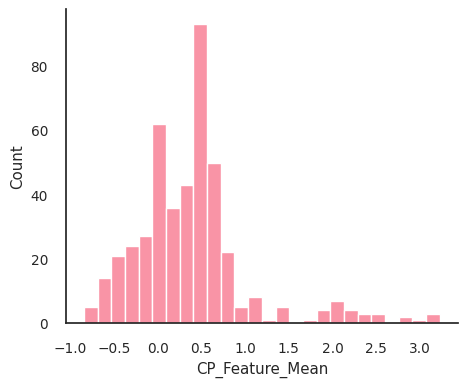

In [170]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [171]:
from utils import *
## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)
## remove corr features
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df, corr_thres=0.9)

Computing UMAP embedding...


<Axes: xlabel='UMAP1', ylabel='UMAP2'>

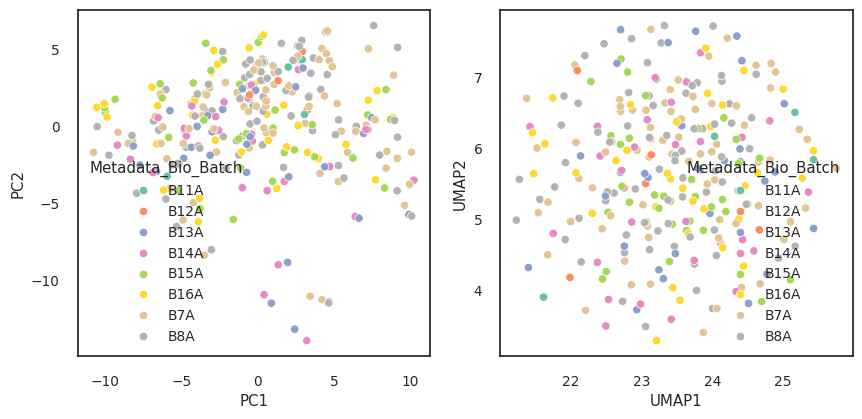

In [172]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
umap_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
pca_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", ax=axes[0],
                hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_Bio_Batch", palette="Set2",  ax=axes[1],
               hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))

__No significant batch effects detected, aggregate the CP profiles to allele level across batches.__

### 2.4 Agg to allele

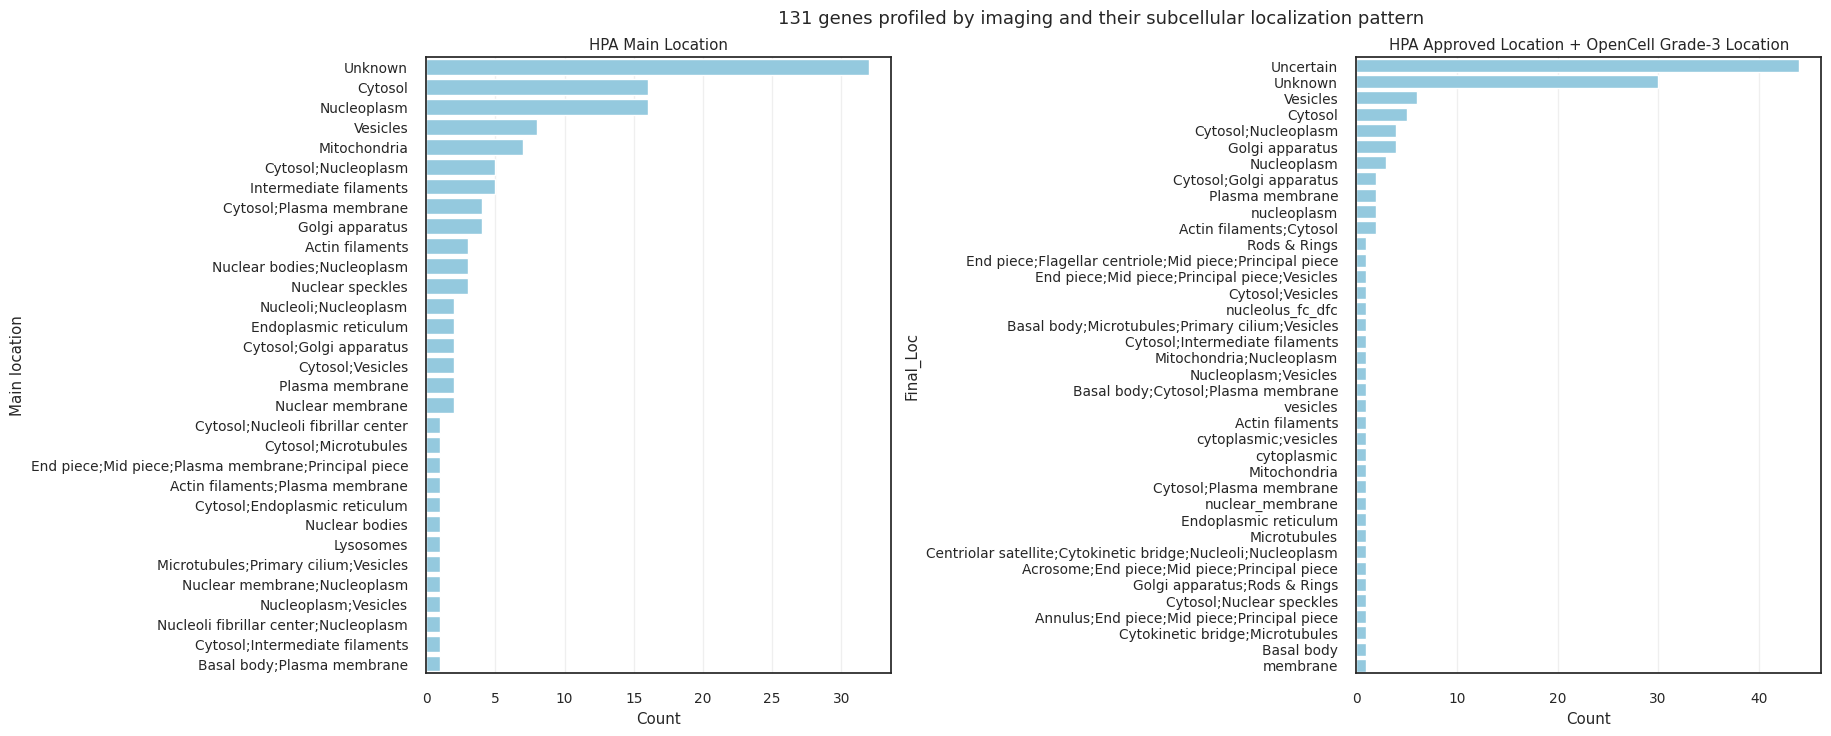

In [174]:
fig, axes = plt.subplots(1,2,figsize=(18, 8))
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Main location",
    ax=axes[0],
    order=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Main location"],
    color="skyblue"
)
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Final_Loc",
    ax=axes[1],
    order=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Final_Loc"],
    color="skyblue"
)
axes[0].grid(axis="x", alpha=.3)
axes[0].set_title("HPA Main Location")

axes[1].grid(axis="x", alpha=.3)
axes[1].set_title("HPA Approved Location + OpenCell Grade-3 Location")

plt.suptitle(f"{ref_batch_proc_prof_loc_df.shape[0]} genes profiled by imaging and their subcellular localization pattern", y=.94)
plt.subplots_adjust(wspace=1.)
custom_palette = sns.color_palette("colorblind", 10) + \
                 sns.color_palette("Set2", 8) + \
                 sns.color_palette("Dark2", 8) + \
                 sns.color_palette("Pastel1", 9)